Particle size distribution as a log-normal RV (Victor Z and David Cole, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $\mathbb{M}_X$ | `M_X` | median particle size (200 $\mu m$) |
| $\mathbb{Q}_X(\alpha)$, $\alpha$ | `Q_alpha`, `alpha` | 90% quantile (400 $\mu m$) |
| $\mu$, $\sigma$ | `mu`, `sigma` | log-normal parameters |
| $F(x)$, $f(x)$ | `F`, `f` | cdf and pdf |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import lognorm
from scipy.special import erfinv

From the data: $\mathbb{M}_X=e^{\mu}=200$, so $\mu=\log 200$; and $\mathbb{Q}_X(0.9)=400$, so

$$\sigma=\frac{\log \mathbb{Q}_X(\alpha)-\mu}{\sqrt{2}\,\mathrm{erf}^{-1}(2\alpha-1)}.$$

In [2]:
M_X = 200
mu = np.log(M_X)
alpha, Q_alpha = 0.9, 400
sigma = (np.log(Q_alpha) - mu) / (np.sqrt(2) * erfinv(2*alpha - 1))
print(f"mu = log(200) = {mu:.3f},  sigma = {sigma:.2f}")

X = lognorm(s=sigma, scale=np.exp(mu))   # scipy: s = sigma, scale = exp(mu)

mu = log(200) = 5.298,  sigma = 0.54


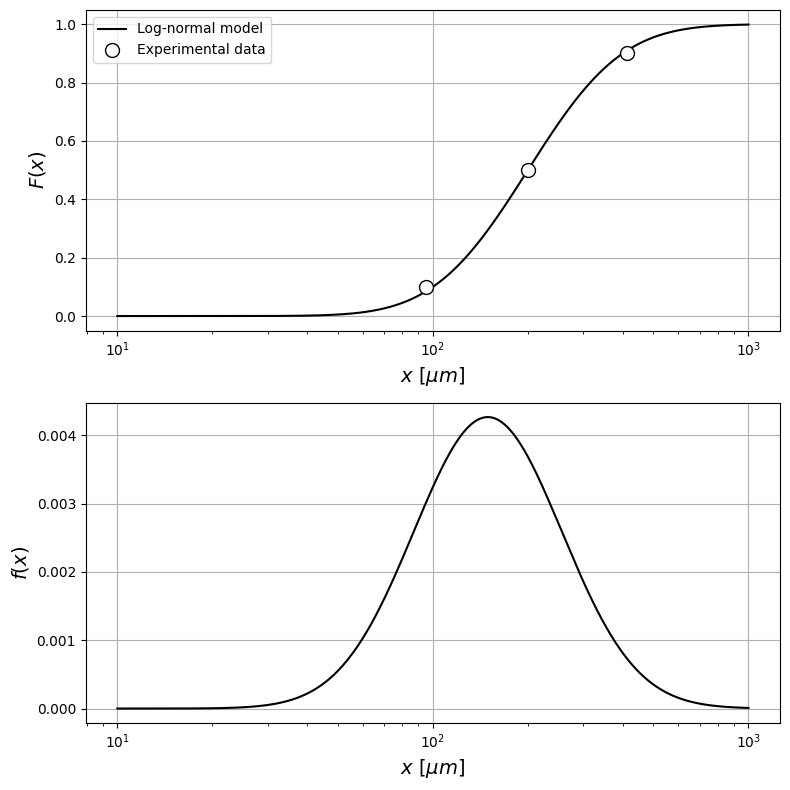

In [3]:
x = np.linspace(10, 1000, 1000)
F_data = [0.1, 0.5, 0.9]                 # experimental cdf values
x_data = [95, 200, 411]

fig, axs = plt.subplots(2, 1, figsize=(8, 8))
axs[0].semilogx(x, X.cdf(x), color='black', linewidth=1.5, label='Log-normal model')
axs[0].plot(x_data, F_data, 'o', markerfacecolor='white', markeredgecolor='black', markersize=10, label='Experimental data')
axs[0].set_ylabel('$F(x)$', fontsize=14)
axs[0].legend(loc='upper left')
axs[1].semilogx(x, X.pdf(x), color='black', linewidth=1.5)
axs[1].set_ylabel('$f(x)$', fontsize=14)
for ax in axs:
    ax.grid(True)
    ax.set_xlabel(r'$x$ [$\mu m$]', fontsize=14)
plt.tight_layout()
plt.show()

Acceptable fraction $\mathbb{P}(250\leq X\leq 400)=F(400)-F(250)$ of a 1000 kg batch.

In [4]:
P_ok = X.cdf(400) - X.cdf(250)
print(f"P(250 <= X <= 400) = {P_ok:.2f}  ->  {1000*P_ok:.0f} kg acceptable")

P(250 <= X <= 400) = 0.24  ->  240 kg acceptable
